In [11]:
from hapi import *
import numpy as np
import matplotlib.pyplot as plt

In [5]:
db_begin("data") #creates a data folder for me to work on
fetch("CO2", 2, 1, 2200, 2400) #(molecule,number in hitran,isotopologue,lower,higher wave.no)

Using data


Data is fetched from http://hitran.org

BEGIN DOWNLOAD: CO2
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/CO2.data
  65536 bytes written to data/

In [51]:
# info("CO2") #to check what was downloaded - info not available for me

In [13]:
nu, coef = absorptionCoefficient_Voigt(
    SourceTables="CO2",
    OmegaRange=[2200, 2400],
    HITRAN_units=True) #wavenumber grid, abs coeff

{'air': 1.0}
7.549667 seconds elapsed for abscoef; nlines = 16405


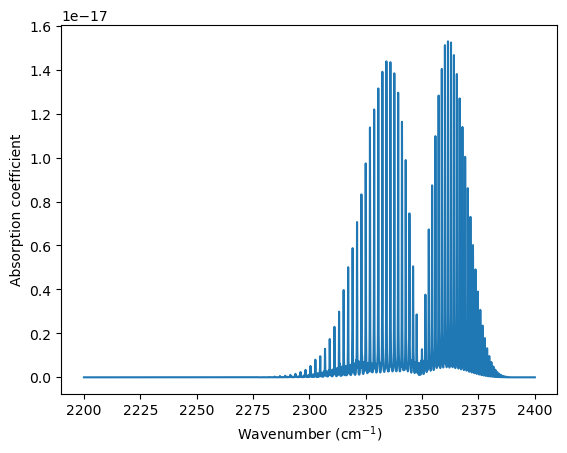

In [15]:
plt.plot(nu, coef)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Absorption coefficient")

plt.show()

In [21]:
print("Number of points:", len(nu))

print("First 10 wavenumbers:")
print(nu[:10])

print("First 10 absorption values:")
print(coef[:10])

print("Minimum absorption:", np.min(coef))
print("Maximum absorption:", np.max(coef))

Number of points: 20001
First 10 wavenumbers:
[2200.   2200.01 2200.02 2200.03 2200.04 2200.05 2200.06 2200.07 2200.08
 2200.09]
First 10 absorption values:
[1.30459096e-25 1.34620165e-25 1.39092118e-25 1.43919629e-25
 1.49155232e-25 1.54885028e-25 1.61135910e-25 1.68021914e-25
 1.75650104e-25 1.84139684e-25]
Minimum absorption: 3.3690578115634765e-26
Maximum absorption: 1.528870538461488e-17


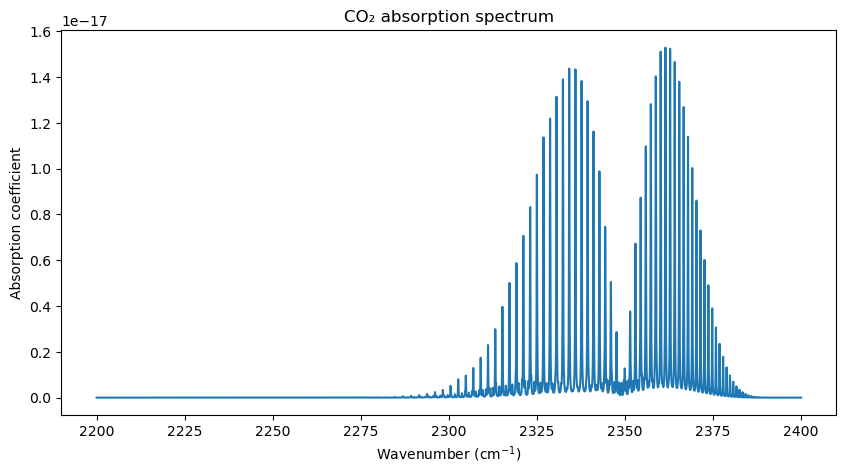

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(nu, coef)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Absorption coefficient")
plt.title("CO₂ absorption spectrum")

plt.show()

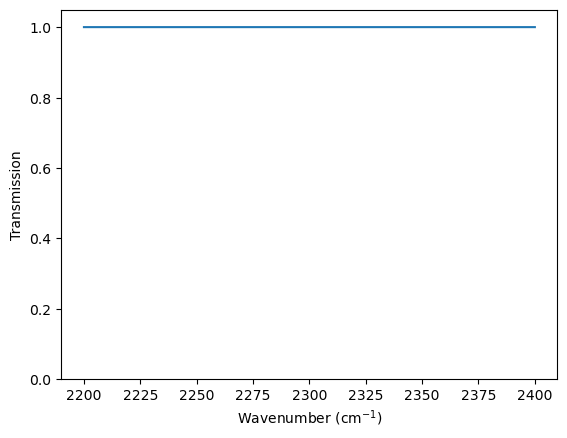

In [25]:
L = 1.0 #length of my gas cell
transmission = np.exp(-coef * L) #beer lamberts law

plt.plot(nu, transmission)

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Transmission")

plt.ylim(0, 1.05)

plt.show()

In [29]:
print(transmission[:10])
print("Minimum transmission:", np.min(transmission))
print("Maximum transmission:", np.max(transmission)) # problem is that my coefficients are waay to small

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Minimum transmission: 1.0
Maximum transmission: 1.0


In [31]:
print("Minimum coefficient =", np.min(coef))
print("Maximum coefficient =", np.max(coef))

print("Coefficient at maximum:")
i = np.argmax(coef)

print("Wavenumber =", nu[i])
print("Coefficient =", coef[i])

Minimum coefficient = 3.3690578115634765e-26
Maximum coefficient = 1.528870538461488e-17
Coefficient at maximum:
Wavenumber = 2361.46
Coefficient = 1.528870538461488e-17


In [35]:
nu, coef = absorptionCoefficient_Voigt(
    SourceTables="CO2",
    OmegaRange=[2200, 2400],
    HITRAN_units=False
)  # we are changing units cause the coeffs are very smol (hitran units=false)

{'air': 1.0}
7.737576 seconds elapsed for abscoef; nlines = 16405


In [37]:
print("Minimum coefficient =", np.min(coef))
print("Maximum coefficient =", np.max(coef))

Minimum coefficient = 8.353147037418371e-07
Maximum coefficient = 379.06385474042196


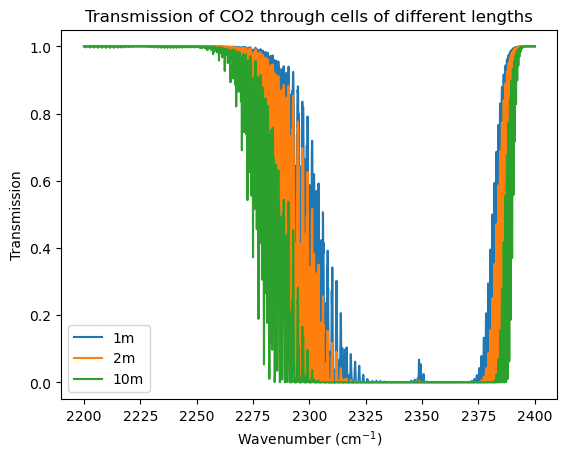

In [49]:
L1 = 1.0
L2=2
L3=10

transmission1 = np.exp(-coef * L1)
transmission2 = np.exp(-coef * L2)
transmission3 = np.exp(-coef * L3)

plt.plot(nu, transmission1,label="1m")
plt.plot(nu, transmission2,label="2m")
plt.plot(nu, transmission3,label="10m")

plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Transmission")
plt.legend()
plt.title("Transmission of CO2 through cells of different lengths")
#plt.ylim(0, 1.05)

plt.show()